# Wstępna Analiza Danych
- Jakub Kwaśniak
- Michał Mizia

## Problem Biznesowy - zadanie

- Czasami oferenci zawyżają ceny, aby nikt w danym okresie nie rezerwował u nich noclegów – jakoś musimy to wykrywać, żeby dało się odpowiednio reagować.

## Zadanie modelowania

* Przygotowanie i porównanie dwóch modeli (bazowego/prostszego i docelowego) rozwiązujących przedstawiony problem klasyfikacji binarnej - odpowiedź na pytanie "czy oferta posiada sztucznie zawyzoną cenę ?"

## Analiza Danych

In [6]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from pprint import pprint

In [7]:
users_df = pd.read_csv("../data/v3/users.csv", skip_blank_lines=False)
users_df.head()

,id,name,surname,city,street,street_number,postal_code
0,45098287.0,NaN,Raczyński,Nowa Sól,Kisielewskiego Stefana,1072.0,NaN
1,508887029.0,Ewa,Szklarska,Cybinka,Ławica,NaN,61-698
2,367991462.0,Kostek,Dębicki,Radzyń Chełmiński,Rollego Karola,NaN,48-273
3,443643923.0,Hanna,Lutostańska,Bystrzyca Kłodzka,Karwowskiego Stanisława,1187.0,11-432
4,NaN,Ryszard,Kot,Karpacz,Nowickiego Maksymiliana,1251.0,51-128


- początkowo, przeanalizowaliśmy z jakich miejscowości pochodzi najwięcej klientów portalu 'Nocarz'

Łącznie miast: 915
Najmniej klientów - 26 osob - pochodzi z Lubaczów,      a najwięcej klientów - 82 osob - pochodzi z Leżajsk


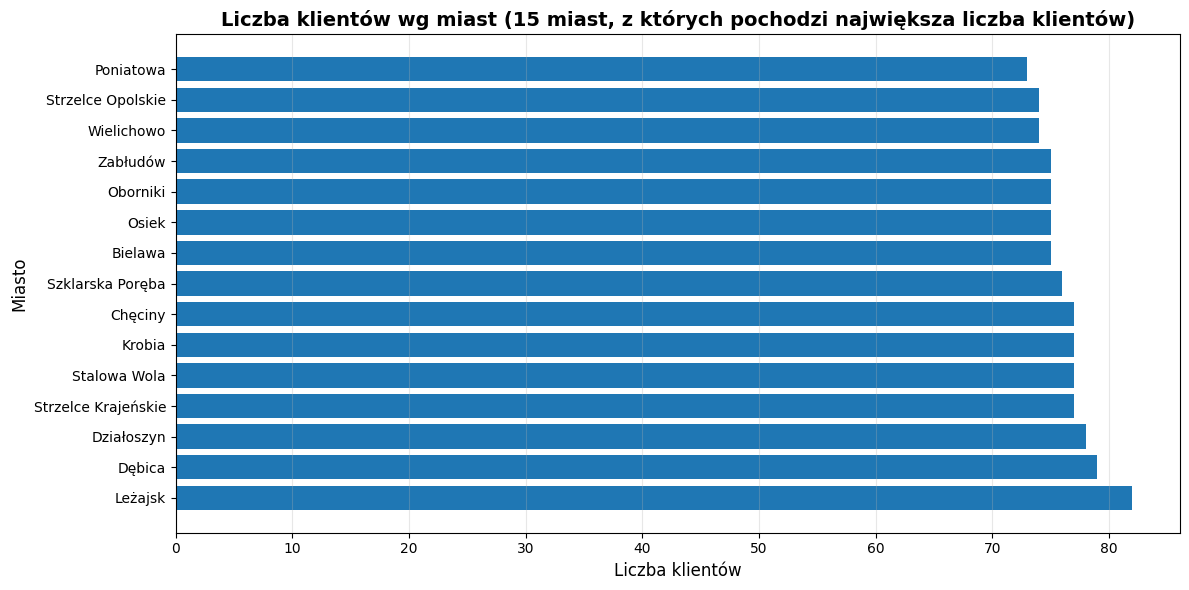

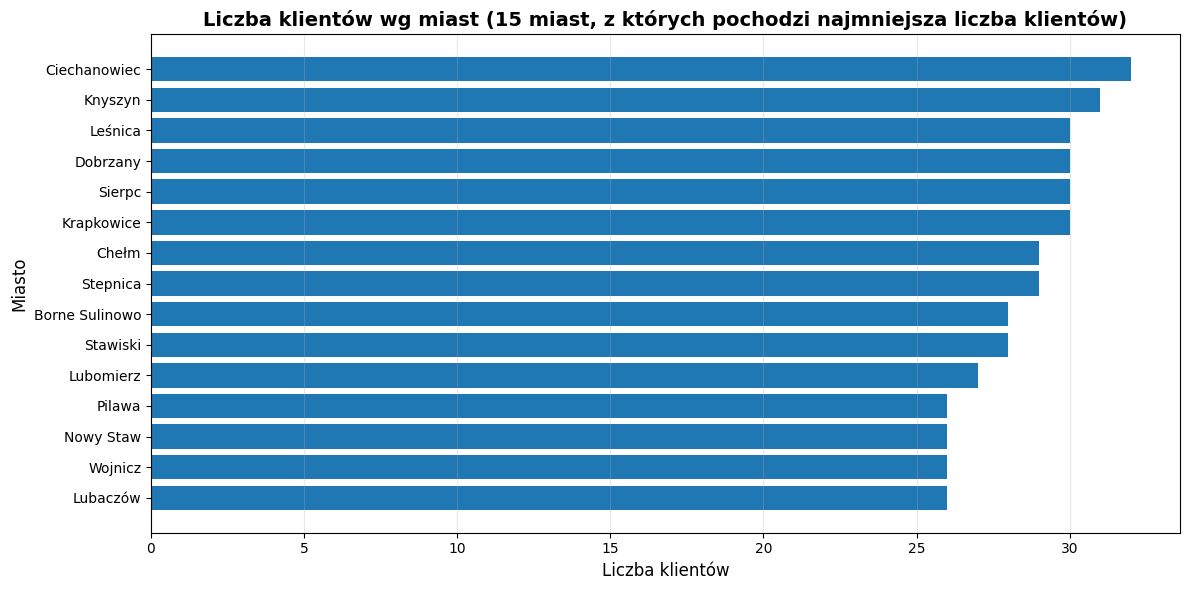

In [8]:

clients_by_city = users_df["city"].value_counts()
print(f"Łącznie miast: {len(clients_by_city)}")

clients_by_city_desc = clients_by_city.sort_values(ascending=False)
clients_by_city_asc = clients_by_city.sort_values(ascending=True)
clients_by_city_asc.values
print(f"Najmniej klientów - {clients_by_city_asc.values[0]} osob - pochodzi z {clients_by_city_asc.index[0]},\
      a najwięcej klientów - {clients_by_city_desc.values[0]} osob - pochodzi z {clients_by_city_desc.index[0]}")


clients_by_city_desc = clients_by_city_desc.head(15)
plt.figure(figsize=(12, 6))
plt.barh(range(len(clients_by_city_desc)), clients_by_city_desc.values)
plt.yticks(range(len(clients_by_city_desc)), clients_by_city_desc.index)
plt.xlabel('Liczba klientów', fontsize=12)
plt.ylabel('Miasto', fontsize=12)
plt.title('Liczba klientów wg miast (15 miast, z których pochodzi największa liczba klientów)', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

clients_by_city_asc = clients_by_city_asc.head(15)
plt.figure(figsize=(12, 6))
plt.barh(range(len(clients_by_city_asc)), clients_by_city_asc.values)
plt.yticks(range(len(clients_by_city_asc)), clients_by_city_asc.index)
plt.xlabel('Liczba klientów', fontsize=12)
plt.ylabel('Miasto', fontsize=12)
plt.title('Liczba klientów wg miast (15 miast, z których pochodzi najmniejsza liczba klientów)', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


- ponizej przygotowane zostały dane z sesji ('sessions') i opinie ('reviews') uytkowników, potrzebne do dalszych analiz  

In [9]:
sessions_df = pd.read_csv("../data/v3/sessions.csv", skip_blank_lines=False)
sessions_df.head(n=10)

,action,user_id,timestamp,listing_id,booking_date,booking_duration,booking_id,price
0,browse_listings,692150.0,2012-02-02T04:32:50.264004,NaN,NaN,NaN,NaN,NaN
1,view_listing,692150.0,2012-02-02T04:55:41.264004,4.984403e+07,NaN,NaN,NaN,NaN
2,view_listing,692150.0,NaN,8.868460e+17,NaN,NaN,NaN,NaN
3,view_listing,692150.0,2012-02-02T04:57:08.264004,4.775150e+05,NaN,NaN,NaN,NaN
4,NaN,692150.0,2012-02-02T04:57:08.264004,4.775150e+05,2012-02-12,10.0,ddbeb971-b8d5-41bc-b86f-3f3abb6a2b16,$305.00
5,browse_listings,3077455.0,2011-11-07T03:40:42.751168,NaN,NaN,NaN,NaN,NaN
6,view_listing,3077455.0,2011-11-07T04:06:04.751168,4.304018e+07,NaN,NaN,NaN,NaN
7,view_listing,NaN,2011-11-07T04:53:16.751168,3.547536e+07,NaN,NaN,NaN,NaN
8,NaN,3077455.0,NaN,8.960827e+17,NaN,NaN,NaN,NaN
9,view_listing,3077455.0,2011-11-07T05:34:45.751168,3.161067e+07,NaN,NaN,NaN,NaN


In [10]:
reviews_df = pd.read_csv("../data/v3/reviews.csv", skip_blank_lines=False)
reviews_df.head()

,listing_id,id,date,reviewer_id,comments,numerical_review
0,477515.0,1875754.0,2012-08-03,692150.0,NaN,5.0
1,477515.0,1928602.0,2012-08-08,3077455.0,This apartment is fantastic! We were 4 people...,5.0
2,477515.0,2092188.0,2012-08-25,NaN,"The apartment was perfect!\r<br/>Well located,...",4.0
3,477515.0,2294712.0,2012-09-14,1299244.0,"Thanks Torsten and Amber for the great stay, t...",5.0
4,NaN,2344903.0,2012-09-19,395390.0,I cannot recommend this apartment enough for t...,NaN


- w następnych analizach wykorzystane zostaną rózniez dane 'kalendarza dostępności i rezerwacji' (calendar) oraz spisu ofert (listings) noclegów w portalu nocarz, posłuzą one do przewidywań występowania / wykrycia anomalii w cenach noclegów 

In [11]:
listings_df = pd.read_csv("../data/v3/listings.csv", skip_blank_lines=False)   # can add index_col="id"
listings_df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2.880673e+07,https://www.nocarz.pl/rooms/28806732,2.024122e+13,2024-12-21,previous scrape,Neukölln Home,"Loft bed, fold out couch, kitchen and balcony ...",NaN,https://a0.muscache.com/pictures/60151487-cc67...,217262525.0,...,5.00,NaN,4.40,NaN,NaN,1.0,1.0,0.0,NaN,0.07
1,1.177924e+06,https://www.nocarz.pl/rooms/1177924,2.024122e+13,2024-12-21,city scrape,Bella Souterrain im Bergmannkiez,The apartment is centrally located in Berlin i...,One of the best locations in Berlin: The holid...,https://a0.muscache.com/pictures/bbaf491b-de11...,NaN,...,4.94,NaN,4.80,First name and Last name: Elisa Behrends <br/>...,NaN,9.0,9.0,NaN,0.0,NaN
2,1.157092e+18,https://www.nocarz.pl/rooms/1157092174752316620,2.024122e+13,2024-12-21,city scrape,NaN,NaN,This furnished apartment is located in Kreuzbe...,https://a0.muscache.com/pictures/prohost-api/H...,434485440.0,...,NaN,NaN,NaN,NaN,t,318.0,318.0,NaN,0.0,NaN
3,4.933665e+06,https://www.nocarz.pl/rooms/4933665,2.024122e+13,NaN,previous scrape,Sunlit 2BR Top Floor Apt in Mitte,Enjoy the open atmosphere of our beautiful apa...,NaN,https://a0.muscache.com/pictures/63146175/0abf...,454103.0,...,4.97,4.84,4.79,01/Z/RA/008539-19,NaN,1.0,1.0,0.0,0.0,0.94
4,NaN,https://www.nocarz.pl/rooms/19518502,NaN,NaN,city scrape,Ruhig und Zentral in Berlin,NaN,NaN,https://a0.muscache.com/pictures/484243f0-fdac...,10364889.0,...,4.86,NaN,NaN,NaN,f,1.0,1.0,NaN,0.0,0.16


In [12]:
listings_df.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'minimum_nights_avg_ntm',
       'maximum_nights_avg_ntm', 'ca

Jak udało się ustalić z klientem podczas wstępnych analiz i zapoznania z problemem, kolumny takie jak:
 * scrape_id, last_scraped, source
są zaszłościami historycznymi i/lub nie wnoszą informacji do analiz, dlatego mogą zostać pominięte w analizach

Podobnie z kolumnami zawierającymi odnośniki/linki do profili i/lub zdjęć hostów:
*  listing_url, picture_url, host_url, host_thumbnail_url, host_picture_url


In [13]:
listings_df.drop(columns=["scrape_id", "last_scraped", "source", "listing_url", "picture_url", "host_url", "host_thumbnail_url", "host_picture_url"], inplace=True)
listings_df.head()

,id,name,description,neighborhood_overview,host_id,host_name,host_since,host_location,host_about,host_response_time,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2.880673e+07,Neukölln Home,"Loft bed, fold out couch, kitchen and balcony ...",NaN,217262525.0,NaN,2018-09-25,NaN,NaN,NaN,...,5.00,NaN,4.40,NaN,NaN,1.0,1.0,0.0,NaN,0.07
1,1.177924e+06,Bella Souterrain im Bergmannkiez,The apartment is centrally located in Berlin i...,One of the best locations in Berlin: The holid...,NaN,Elisa,2013-05-17,NaN,"Hallo, ich bin Elisa. Ich lebe mit meiner Fami...",NaN,...,4.94,NaN,4.80,First name and Last name: Elisa Behrends <br/>...,NaN,9.0,9.0,NaN,0.0,NaN
2,1.157092e+18,NaN,NaN,This furnished apartment is located in Kreuzbe...,434485440.0,Blueground,2021-12-03,"Berlin, Germany","We’re Blueground, a global proptech company wi...",NaN,...,NaN,NaN,NaN,NaN,t,318.0,318.0,NaN,0.0,NaN
3,4.933665e+06,Sunlit 2BR Top Floor Apt in Mitte,Enjoy the open atmosphere of our beautiful apa...,NaN,454103.0,Benjamin,2011-03-21,"Berlin, Germany",Concert pianist based in Berlin. Plant grower ...,NaN,...,4.97,4.84,4.79,01/Z/RA/008539-19,NaN,1.0,1.0,0.0,0.0,0.94
4,NaN,Ruhig und Zentral in Berlin,NaN,NaN,10364889.0,Insa,2013-12-01,"Berlin, Germany",Insa aus Berlin.,within a few hours,...,4.86,NaN,NaN,NaN,f,1.0,1.0,NaN,0.0,0.16


- nalezy dostosować niektóre kolumny do przeprowadzenia analiz, np. zmodyfikować 'price' by dało się je serializować do wartości liczbowej

In [14]:
listings_df["price_numeric"] = listings_df["price"].str.replace('$', '').str.replace(',', '').astype(float)

In [15]:
print(f"Liczba wszystkich ofert: {len(listings_df.index)}")
print(f"Liczba ofert bez podanej ceny bazowej noclegu: {listings_df['price_numeric'].isna().sum()}")

Liczba wszystkich ofert: 1449
Liczba ofert bez podanej ceny bazowej noclegu: 273


- __jak widać ponad 1/3 spośród ofert noclegowych (listingów) wybrakowaną jedną z kluczowych wartości - bazową cenę noclegu__

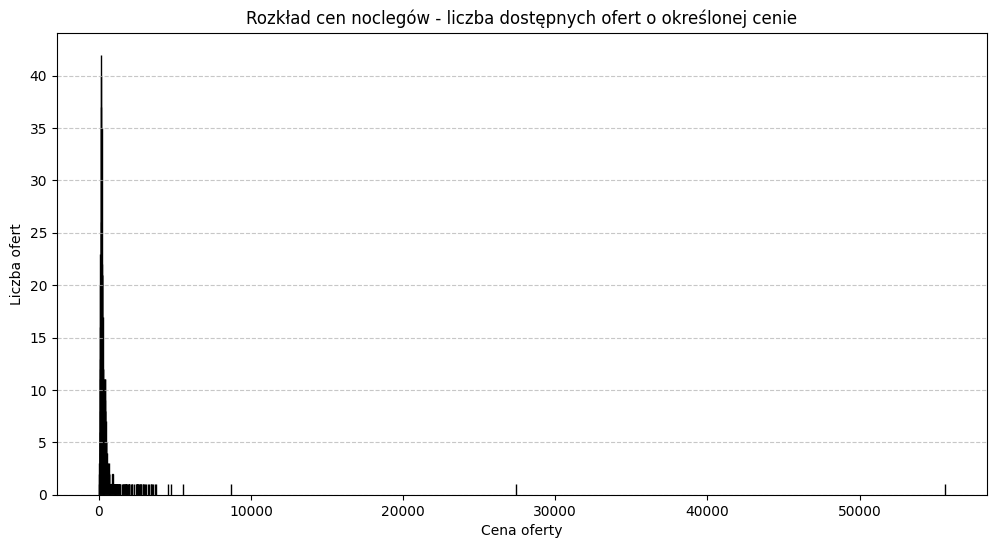

In [16]:
prices_distro = listings_df["price_numeric"].value_counts(dropna=True)
plt.figure(figsize=(12, 6))

plt.bar(prices_distro.index, prices_distro.values, color=["skyblue", "orange"], edgecolor="black")
plt.title("Rozkład cen noclegów - liczba dostępnych ofert o określonej cenie")
plt.xlabel("Cena oferty")
plt.ylabel("Liczba ofert")
# plt.xticks(prices_distro.index)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [17]:
price_info = listings_df["price_numeric"].dropna()

price_distro_info = {
    "min": price_info.min(),
    "max": price_info.max(),
    "median": price_info.median(),
    "mean": price_info.mean(),
    "std": price_info.std()
}

print("Rozkład bazowych cen noclegów:")
price_distro_info

Rozkład bazowych cen noclegów:


{'min': 30.0,
 'max': 55582.13,
 'median': 210.0,
 'mean': 461.44394557823125,
 'std': 1889.620567811453}

- jak mozna zauwazyc, odchylenie standardowe jest bardzo wysokie, co wskazuje na duza rónorodność w zakresie cen noclegów oferowanych przez portal klienta
- jednakze, najczęściej występujące ceny oferowane noclegów, jak i średnia wszystkich cen znajdują się w okolicy ceny 100-150 $
 

__Dane pokazują, iz w ofercie portalu znajdują się noclegi z róznych półek cenowych, natomiast nie pozwala to stwierdzić, czy w zdarzały się sytuacje sztucznego zawyzania cen. W celu wyciągnięcia wstępnych wniosków o wachaniach cen ofert przeanalizowane zostaną dane z spisu kalendarzowego (calendar.csv) dostarczające informacje o cenie noclegu oraz stanie rezerwacji w danym dniu__

In [18]:
calendar_df = pd.read_csv("../data/v3/calendar.csv", skip_blank_lines=False)
calendar_df.head()

,listing_id,date,available,price,adjusted_price,minimum_nights,maximum_nights
0,20858.0,2024-12-21,f,$780.00,NaN,3.0,1125.0
1,20858.0,NaN,f,$780.00,NaN,3.0,1125.0
2,20858.0,2024-12-23,f,$780.00,NaN,NaN,1125.0
3,20858.0,2024-12-24,NaN,$780.00,NaN,3.0,1125.0
4,NaN,2024-12-25,t,NaN,NaN,3.0,1125.0


- w wyniku rozmowy z klientem ustalone zostało, ze kolumna 'adjusted_price' zostanie pominieta w wstępnych analizach, gdyz klient nie jest w stanie dostarczyć tych danych
- dlatego kolumna 'price' została uzyta jako niosąca informacje o cenie w danym okresie (wartość inna niz cena bazowa, dostosowana do popytu związanego z sezonowością)

- ponizej przedstawiona jest średnia kwartalna cena losowej oferty portalu 'Nocarz' 

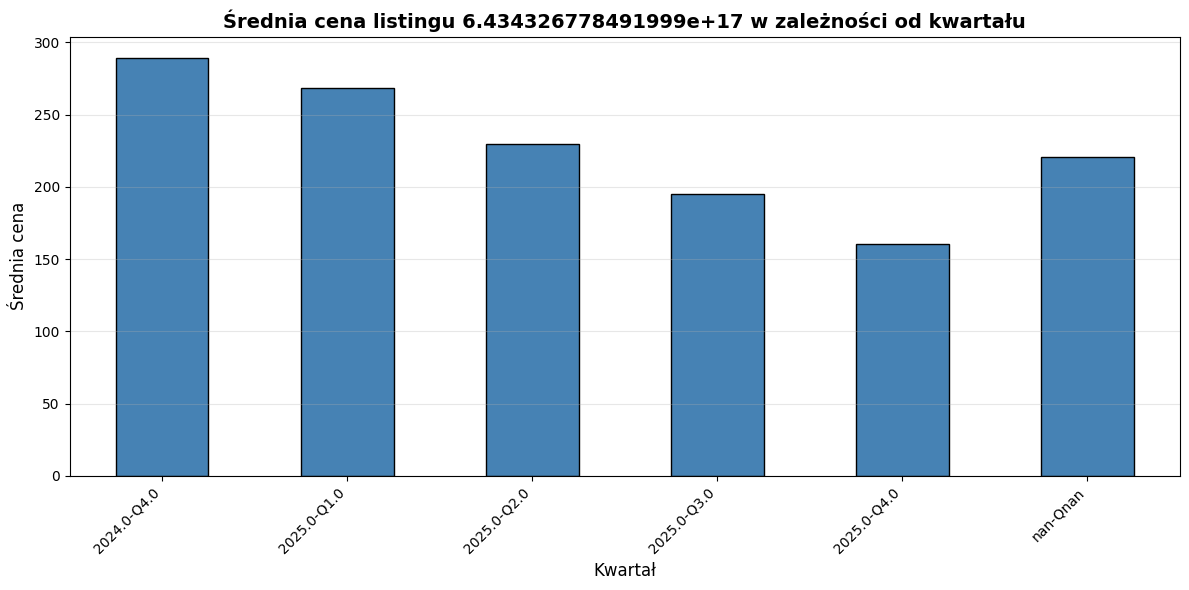

Listing ID: 6.434326778491999e+17

Średnie ceny po kwartale:
year_quarter
2024.0-Q4.0    289.432000
2025.0-Q1.0    268.607857
2025.0-Q2.0    229.536222
2025.0-Q3.0    195.371698
2025.0-Q4.0    160.382821
nan-Qnan       220.962564
Name: price_numeric, dtype: float64


In [19]:
mod_calendar_df = calendar_df.copy()
mod_calendar_df["price_numeric"] = mod_calendar_df["price"].str.replace('$', '').str.replace(',', '').astype(float)
mod_calendar_df["date"] = pd.to_datetime(mod_calendar_df["date"])

mod_calendar_df["year_quarter"] = mod_calendar_df["date"].dt.year.astype(str) + '-Q' +  mod_calendar_df["date"].dt.quarter.astype(str)

# each time random listing data is checked
listing_id = mod_calendar_df['listing_id'].iloc[np.random.choice(range(len(mod_calendar_df['listing_id'])))]
listing_prices = mod_calendar_df[mod_calendar_df['listing_id'] == listing_id].copy()

quarterly_avg = listing_prices.groupby('year_quarter')['price_numeric'].mean()

plt.figure(figsize=(12, 6))
quarterly_avg.plot(kind="bar", color="steelblue", edgecolor="black")
plt.xlabel("Kwartał", fontsize=12)
plt.ylabel("Średnia cena", fontsize=12)
plt.title(f"Średnia cena listingu {listing_id} w zależności od kwartału", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Listing ID: {listing_id}\n")
print(f"Średnie ceny po kwartale:\n{quarterly_avg}")

- Jak widać, średnia cena oferty czy tez jej odchylenie w danym kwartale pozostają stałe więc zawyzanie cen prawdopodobnie nie będzie związane z sezonowością

Teraz przeprowadzona zostanie analiza cen noclegów z perspektywy dziennej 

In [20]:
listings_price_distro = {}

for listing_id in mod_calendar_df['listing_id'].unique():
    listing_per_id_df = mod_calendar_df[mod_calendar_df['listing_id'] == listing_id].copy()
    listing_prices = listing_per_id_df["price_numeric"]
    listings_price_distro[listing_id] = {
        "min": listing_prices.min(),
        "max": listing_prices.max(),
        "mean": listing_prices.mean(),
        "median": listing_prices.median(),
        "std": listing_prices.std()
    }

pprint(listings_price_distro)


{20858.0: {'max': 780.0,
           'mean': 581.1096943231441,
           'median': 581.18,
           'min': 390.0,
           'std': 114.07348094421732},
 nan: {'max': nan, 'mean': nan, 'median': nan, 'min': nan, 'std': nan},
 29279.0: {'max': 310.0,
           'mean': 231.1669298245614,
           'median': 229.45999999999998,
           'min': 155.0,
           'std': 45.297633514194125},
 64014.0: {'max': 810.0,
           'mean': 602.5626521739131,
           'median': 595.59,
           'min': 405.0,
           'std': 119.01350326092178},
 81081.0: {'max': 280.0,
           'mean': 207.6486956521739,
           'median': 205.88,
           'min': 140.0,
           'std': 40.91536058640693},
 85560.0: {'max': 400.0,
           'mean': 297.92475,
           'median': 298.04,
           'min': 200.0,
           'std': 57.26364691213636},
 117649.0: {'max': 650.0,
            'mean': 487.90353711790397,
            'median': 490.69,
            'min': 325.0,
            'std': 97.59

In [21]:
nonzero_std_listings = [listing_id for listing_id in listings_price_distro if listings_price_distro[listing_id]["std"] != 0]
print(f"Liczba ofert o nie-zerowym odchyleniu standardowym cen z badanego okresu: {len(nonzero_std_listings)}")

Liczba ofert o nie-zerowym odchyleniu standardowym cen z badanego okresu: 1450


- cena 'price' przedstawiona w spisie kalendarzowym dostępnych noclegów (calendar.csv) jest stała i nie zmienia się w kolejnych dniach (czy tez kwartałach) obowiązywania oferty

Ponizej zbadany został wpływ lokalizacji na wybór oferty noclegu  

In [22]:
neighbourhood_nan_counter = 0
unique_listings = mod_calendar_df["listing_id"].unique()
city_availability_relation = {}

for listing_id in unique_listings:
    data_per_listing = mod_calendar_df[mod_calendar_df["listing_id"] == listing_id]

    neighbourhood = listings_df.loc[listings_df["id"] == listing_id, "neighbourhood_group_cleansed"]
    if not neighbourhood.empty:
        neighbourhood = neighbourhood.iloc[0] 
        if neighbourhood not in city_availability_relation:
            city_availability_relation[neighbourhood] = 0
        city_availability_relation[neighbourhood] += data_per_listing["available"].eq("f").sum()
    else:
        neighbourhood_nan_counter += 1

print(f"Sposród wszsystkich ofert, n={neighbourhood_nan_counter} ofert nie ma podanej dzielnicy")
city_availability_relation

Sposród wszsystkich ofert, n=315 ofert nie ma podanej dzielnicy


{'Pankow': 19589,
 'Mitte': 25702,
 'Friedrichshain-Kreuzberg': 29036,
 'Tempelhof - Schöneberg': 10586,
 nan: 35878,
 'Neukölln': 19082,
 'Reinickendorf': 2017,
 'Treptow - Köpenick': 4131,
 'Charlottenburg-Wilm.': 11551,
 'Steglitz - Zehlendorf': 4305,
 'Spandau': 1352,
 'Marzahn - Hellersdorf': 533,
 'Lichtenberg': 3017}

C:\Users\Michal\AppData\Local\Temp\ipykernel_28368\812507232.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Liczba rezerwacji (w dniach)", y="Dzielnica", data=df, palette="Blues_r")


<Axes: xlabel='Liczba rezerwacji (w dniach)', ylabel='Dzielnica'>

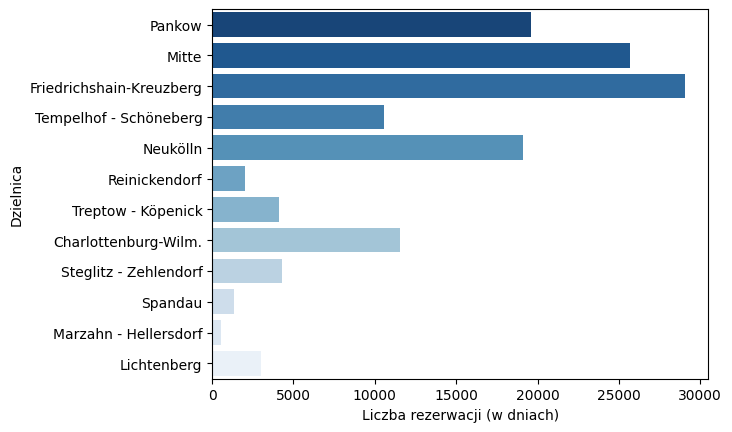

In [23]:
series = pd.Series(city_availability_relation).dropna()   

df = series.reset_index().rename(columns={0:"Liczba rezerwacji (w dniach)", "index": "Dzielnica"})
sns.barplot(x="Liczba rezerwacji (w dniach)", y="Dzielnica", data=df, palette="Blues_r")

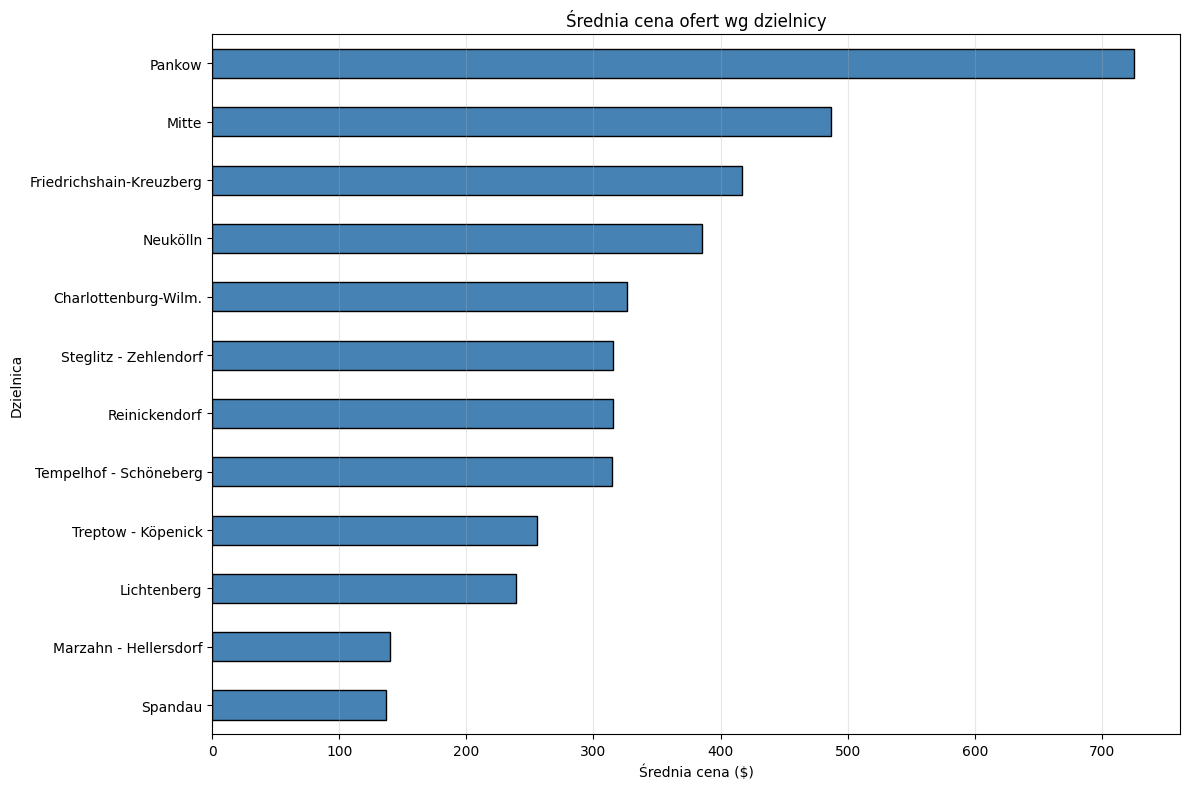

In [24]:
listings_df["price_numeric"] = listings_df["price"].str.replace("$", "").str.replace(",", "").astype(float) 
avg_price_by_district = (
    listings_df.groupby("neighbourhood_group_cleansed")["price_numeric"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(12, 8))
avg_price_by_district.plot(kind="barh", color="steelblue", edgecolor="black")
plt.xlabel("Średnia cena ($)")
plt.ylabel("Dzielnica")
plt.title("Średnia cena ofert wg dzielnicy")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

- z powyzszych wykresów wynika, ze największą liczbę rezerwacji notują dzielnica o średniej cenie ofert noclegów > 100 $ (być moze klienci wbierają dzielnice drozsze a cieszące się lepszą renomą i warunkami)

Ponizej sprawdzona zosatała dostępność noclegów w zalezności od ceny oferty 

In [25]:
unqiue_prices = [price for price in mod_calendar_df["price_numeric"].unique()]
price_availability_relation = {}

for price in unqiue_prices:
    data_per_price = mod_calendar_df[mod_calendar_df["price_numeric"] == price]
    price_availability_relation[price] = data_per_price["available"].eq("f").sum()  # available == f(alse)
    

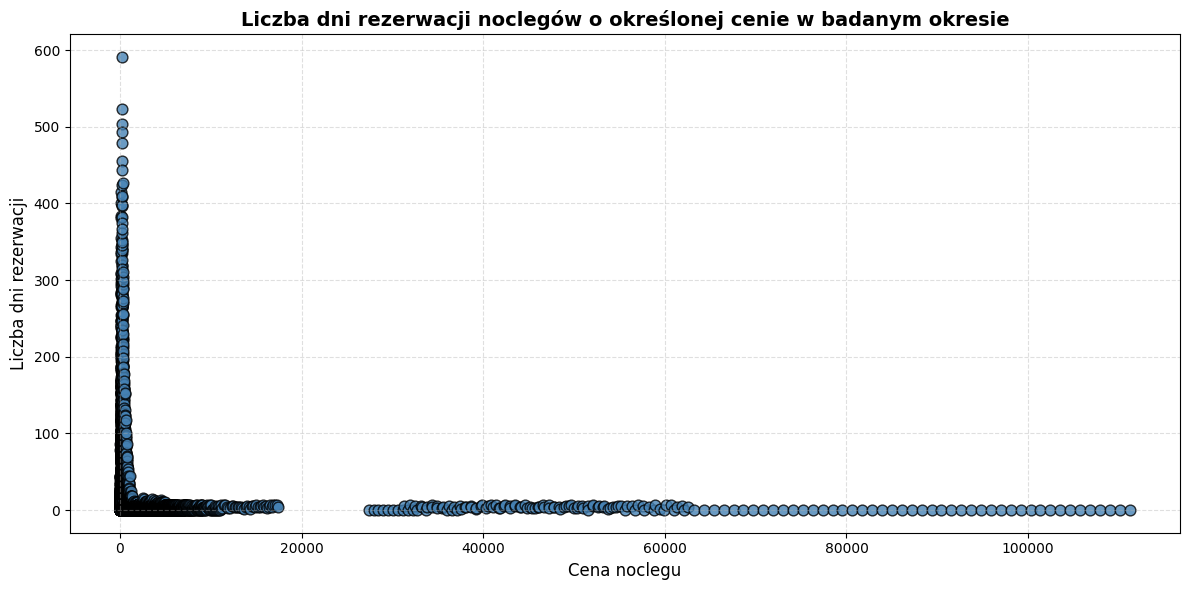

In [26]:
prices = sorted(price_availability_relation.keys())
reservations = [price_availability_relation[price] for price in prices]

plt.figure(figsize=(12, 6))
plt.scatter(prices, reservations, color="steelblue", edgecolors="black", alpha=0.8, s=60)
plt.title("Liczba dni rezerwacji noclegów o określonej cenie w badanym okresie", fontsize=14, fontweight="bold")
plt.xlabel("Cena noclegu", fontsize=12)
plt.ylabel("Liczba dni rezerwacji", fontsize=12)
plt.grid(axis="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

- Jak widać, najwięcej rezerwacji (zarezerwowanych noclegów w dniach/dobach) notowane jest dla ofert o niskich cenach. Natomiast zdarzają się równiez noclegi o cenie znacząco wyzszej niz średnia, a cieszące się dosyć duzą popularnością wśród klientów - przykładem jest oferta noclegu o cenie 6000$/dobę, której liczba rezerwacji przekracza wiele liczbę rezerwacji wielu ofert z zakresu cenowego 0-1000$ (co widoczne jest na powyzszym wykresie) 

In [30]:
# Peer-group price distribution: Reinickendorf, Entire home/apt, July
NEIGHBOURHOOD_GROUP_CLEANSED = "Reinickendorf"
ROOM_TYPE = "Entire home/apt"
LISTING_MONTH = 7

lst_idx = listings_df.drop_duplicates(subset="id").set_index("id")

cal_price = calendar_df["price"].str.replace("$", "", regex=False).str.replace(",", "").astype(float)
cal_month = pd.to_datetime(calendar_df["date"]).dt.month

cell_mask = (
    (calendar_df["listing_id"].map(lst_idx["neighbourhood_group_cleansed"]) == NEIGHBOURHOOD_GROUP_CLEANSED)
    & (calendar_df["listing_id"].map(lst_idx["room_type"]) == ROOM_TYPE)
    & (cal_month == LISTING_MONTH)
)
cell_prices = cal_price[cell_mask]

print("rows:", len(cell_prices), "| unique listings:", calendar_df.loc[cell_mask, "listing_id"].nunique())
print(f"mean:    {cell_prices.mean():.2f}")
print(f"median:  {cell_prices.median():.2f}")
print(f"std:     {cell_prices.std():.2f}")
print(f"p90:     {cell_prices.quantile(0.90):.2f}")
print(f"max:     {cell_prices.max():.2f}")
print()
print(f"mean + 0.5*std threshold (v1 heuristic): {cell_prices.mean() + 0.5*cell_prices.std():.2f}")

rows: 204 | unique listings: 11
mean:    396.51
median:  365.00
std:     169.72
p90:     644.12
max:     727.94

mean + 0.5*std threshold (v1 heuristic): 481.37


### Wnioski + Hipoteza: 

- dane z users.csv, sessions.csv wykazują niską informatywność w analizach i prawdopodobnie nie wniosą wysokiej wartości do predykcji przygotowanych modeli

- z review.csv wykorzystane zostaną opienie (comments) oraz numeryczna ocena (numerical_review) oraz daty wystawienia opinii, informacje będą powiązane z ofertami przez listing_id

- główne analizy i przygotowane modele zostaną oparte o dane z calendar.csv oraz listings.csv 